In [ ]:
!pip install --quiet datasets

In [ ]:
import matplotlib.pyplot as plt
from torchvision import transforms

In [ ]:
from datasets import load_dataset

ds_stream = load_dataset("none-yet/anime-captions", streaming=True)

Resolving data files:   0%|          | 0/64 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/64 [00:00<?, ?it/s]

Примеров: 122
Текст первой картинки: A close-up portrait of a young woman with long, flowing green hair, wearing a colorful kimono. Her hair is decorated with pink and red flowers, and she has a gentle, slightly smiling expression.
Форма картинки: (512, 512)



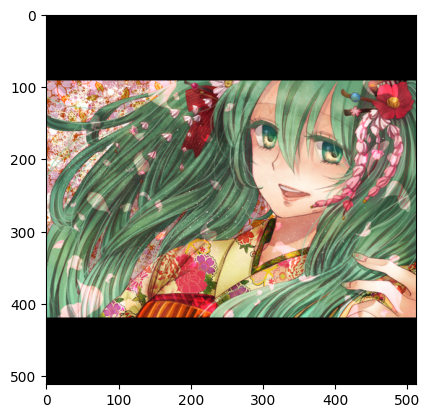


Отфильтрованных картинок: 7


In [ ]:
FILTER_WORDS = [
    "nsfw", "naked", "lewd", "undressed", "lingerie",
    "underwear", "panties", "cleavage", "suggestive",
    "bound", "fetish", "chest", "sensual", "exposed"
]

stats = {"filtered_count": 0}

def safe_samples_filter(example):
    caption = example['text'].lower()
    if not any([word in caption for word in FILTER_WORDS]) == False:
        stats['filtered_count'] += 1
        # plt.imshow(example['image'])
        # plt.show()
        return False
    return True

index = 0

mini_batch = list(ds_stream["train"].filter(safe_samples_filter).take(122))

print(f"Примеров: {len(mini_batch)}")
print("Текст первой картинки:", mini_batch[index]['text'])

img = mini_batch[index]['image']

print(f"Форма картинки: {img.size}\n")

plt.imshow(img)
plt.show()

print(f"\nОтфильтрованных картинок: {stats['filtered_count']}")

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

img_tensor = transform(img)

print(img_tensor.max())
print(img_tensor.min())
print(img_tensor.mean())
print(img_tensor.std())

tensor(1.)
tensor(-1.)
tensor(-0.3207)
tensor(0.6282)
